In [10]:
from pathlib import Path
import pandas as pd

CSV_PATH = Path("historique_merged.csv")

with CSV_PATH.open("rb") as f:
    nb_lignes = sum(1 for _ in f)
print(f"{nb_lignes:,} lignes dans le fichier".replace(",", " "))

FileNotFoundError: [Errno 2] No such file or directory: 'historique_merged.csv'

In [ ]:
df = pd.read_csv(CSV_PATH, header=None)
print(df.shape)
df.head()

(3757220, 8)


,0,1,2,3,4,5,6,7
0,2026-10-16T11:52Z,10003,17,1,1,Hauteville - Bonne Nouvelle,"48.87077,2.34965",True
1,2026-10-16T11:52Z,10004,48,1,4,Metz - Faubourg Saint-Denis,"48.87089,2.35352",True
2,2026-10-16T11:52Z,10005,17,0,9,Petites Ecuries - Faubourg Poissonnière,"48.87397,2.34839",True
3,2026-10-16T11:52Z,10006,28,3,20,Petites Ecuries - Faubourg Saint-Denis,"48.87287,2.35422",True
4,2026-10-16T11:52Z,10008,18,4,2,Cité Riverin - Château d'Eau,"48.87070,2.35874",True


In [ ]:
# Renommer les colonnes et convertir les types de données
COLONNES = [
    "horodatage", "station_code", "capacity", "velo_meca", "velo_elec",
    "station_name", "coordonnees", "operative",
]

df = pd.read_csv(CSV_PATH, header=None, names=COLONNES)
df["horodatage"] = pd.to_datetime(df["horodatage"], utc=True)
df[["latitude", "longitude"]] = df["coordonnees"].str.split(",", expand=True).astype(float)
df = df.drop(columns="coordonnees")

In [ ]:
# Fusion des colonnes "velo_meca" et #velo_elec" pour créer une nouvelle colonne "available" 
df["available"] = df["velo_meca"] + df["velo_elec"]

In [ ]:
# Ecarter les stations en dehors de Paris 
dans_paris = df["latitude"].between(48.815, 48.902) & df["longitude"].between(2.224, 2.470)
df = df[dans_paris].copy()

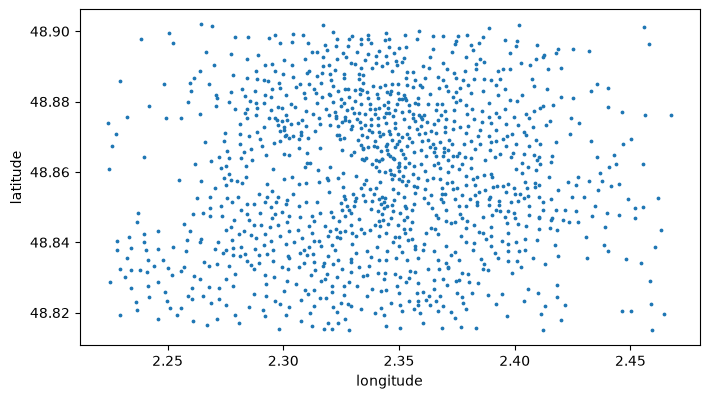

In [ ]:
# Voir ce que ça donne sur une carte 
import numpy as np

stations = df.drop_duplicates("station_code")
ax = stations.plot.scatter(x="longitude", y="latitude", s=3, figsize=(8, 8))
ax.set_aspect(1 / np.cos(np.radians(48.86)))

In [ ]:
# Suppressions des stations à capacité nulle (0)
df = df[df["capacity"] > 0].copy()

In [ ]:
# Vérification 
print(df["capacity"].min()) 
print((df["capacity"] == 0).sum())

11
0


In [ ]:
# Je vais chercher à isoler les cas problématiques, c-à-d les stations où la capacité est inférieur aux nombres de vélos dispo
anomalies = df[df["available"] > df["capacity"]].copy()
anomalies["exces"] = anomalies["available"] - anomalies["capacity"]

print(f"{len(anomalies):,} lignes sur {len(df):,} ({len(anomalies) / len(df):.2%})")
print(f"{anomalies['station_code'].nunique()} stations sur {df['station_code'].nunique()}")
anomalies["exces"].describe()

7,463 lignes sur 3,004,147 (0.25%)
17 stations sur 1215


count    7463.000000
mean        9.544687
std         8.191153
min         1.000000
25%         3.000000
50%         7.000000
75%        14.000000
max        40.000000
Name: exces, dtype: float64

In [ ]:
# Trouver les cas les plus extrêmes 
anomalies.sort_values("exces", ascending=False).head(10)[
    ["horodatage", "station_code", "station_name", "capacity", "velo_meca", "velo_elec", "operative", "exces"]
]

,horodatage,station_code,station_name,capacity,velo_meca,velo_elec,operative,exces
3250133,2026-10-24 14:25:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,46,36,True,40
3247095,2026-10-24 14:15:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,46,36,True,40
3259247,2026-10-24 14:55:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3257728,2026-10-24 14:50:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3256209,2026-10-24 14:45:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3254690,2026-10-24 14:40:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3253171,2026-10-24 14:35:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3251652,2026-10-24 14:30:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3248614,2026-10-24 14:20:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,46,36,True,40
3245576,2026-10-24 14:10:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,46,36,True,40


In [ ]:
# 1. Lignes entièrement identiques (toutes les occurrences marquées)
full_dups = df[df.duplicated(keep=False)]

In [ ]:
# 2. Doublons sur la clé logique : même station au même instant
key_dups = df[df.duplicated(subset=["horodatage", "station_code"], keep=False)]
key_dups = key_dups.sort_values(["station_code", "horodatage"])

In [ ]:
print(f"Lignes identiques : {len(full_dups)}")
print(f"Doublons (timestamp, station_id) : {len(key_dups)}")
print(key_dups)

Lignes identiques : 0
Doublons (timestamp, station_id) : 0
Empty DataFrame
Columns: [horodatage, station_code, capacity, velo_meca, velo_elec, station_name, operative, latitude, longitude, available]
Index: []


In [ ]:
# 3. Pour nettoyer en gardant la première occurrence mais pas besoin parce que pas de doublons
df = df.drop_duplicates(subset=["horodatage", "station_code"], keep="first")

Création d'une variable cible

In [ ]:
# trie selon le code de station et l'heure pour compter la disponibilité dans 30 min
df = df.sort_values(["station_code", "horodatage"]).reset_index(drop=True)


In [ ]:
# On cherche la ligne exactement 30 min plus tard
future = df[["station_code", "horodatage", "available"]].copy()
future["horodatage"] = future["horodatage"] - pd.Timedelta(minutes=30)
future = future.rename(columns={"available": "available_t30"})

In [ ]:
df = df.merge(future, on=["station_code", "horodatage"], how="left")
# pour convertir en Int et pas float
df["available_t30"] = df["available_t30"].astype("Int64")

In [ ]:
df

,horodatage,station_code,capacity,velo_meca,velo_elec,station_name,operative,latitude,longitude,available,available_t30
0,2026-10-16 11:52:00+00:00,1001,17,2,9,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,11,<NA>
1,2026-10-16 12:12:00+00:00,1001,17,2,9,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,11,<NA>
2,2026-10-16 12:21:00+00:00,1001,17,2,8,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,10,<NA>
3,2026-10-16 13:20:00+00:00,1001,17,2,5,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,7,14
4,2026-10-16 13:25:00+00:00,1001,17,2,5,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,7,13
...,...,...,...,...,...,...,...,...,...,...,...
3004142,2026-10-25 18:15:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,<NA>
3004143,2026-10-25 18:20:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,<NA>
3004144,2026-10-25 18:25:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,<NA>
3004145,2026-10-25 18:30:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,<NA>


In [ ]:
# Pour répérer les nan pour voir la proportion des données manquantes
n_na = df["available_t30"].isna().sum()
print(f"NA : {n_na} / {len(df)} ({n_na / len(df):.1%})")

NA : 133647 / 3004147 (4.4%)


In [ ]:
# ecarter des valeurs manquantes après le shift
df = df.dropna(subset=["available_t30"]).reset_index(drop=True)

In [ ]:
# introduire la tendance
df["delta_t30"] = df["available_t30"] - df["available"]

# Catégorie lisible le stock monte, baisse ou reste stable
df["tendance"] = pd.cut(
    df["delta_t30"],
    bins=[-float("inf"), -1, 0, float("inf")],
    labels=["baisse", "stable", "hausse"],
)

In [ ]:
df

,horodatage,station_code,capacity,velo_meca,velo_elec,station_name,operative,latitude,longitude,available,available_t30,delta_t30,tendance
0,2026-10-16 13:20:00+00:00,1001,17,2,5,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,7,14,7,hausse
1,2026-10-16 13:25:00+00:00,1001,17,2,5,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,7,13,6,hausse
2,2026-10-16 13:35:00+00:00,1001,17,7,7,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,14,13,-1,baisse
3,2026-10-16 13:40:00+00:00,1001,17,7,7,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,14,13,-1,baisse
4,2026-10-16 13:45:00+00:00,1001,17,7,7,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,14,13,-1,baisse
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2870495,2026-10-25 17:45:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0,0,stable
2870496,2026-10-25 17:50:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0,0,stable
2870497,2026-10-25 17:55:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0,0,stable
2870498,2026-10-25 18:00:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0,0,stable


In [ ]:
# introduire representation cyclique de heure
h = df["horodatage"].dt.tz_convert("Europe/Paris")
heure_dec = h.dt.hour + h.dt.minute / 60

df["heure_sin"] = np.sin(2 * np.pi * heure_dec / 24)
df["heure_cos"] = np.cos(2 * np.pi * heure_dec / 24)

In [ ]:
# introduire is weekend
df["is_weekend"] = df["horodatage"].dt.tz_convert("Europe/Paris").dt.dayofweek >= 5
df

/var/folders/xr/xtxsn2rd4yn4192ld1lxr_km0000gn/T/ipykernel_2651/560609140.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["is_weekend"] = df["horodatage"].dt.tz_convert("Europe/Paris").dt.dayofweek >= 5


,horodatage,station_code,capacity,velo_meca,velo_elec,station_name,operative,latitude,longitude,available,available_t30,delta_t30,tendance,is_weekend,heure,delta_abs,rush,heure_sin,heure_cos
0,2026-10-16 13:20:00+00:00,1001,17,2,5,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,7,14,7,hausse,False,15,7,False,-0.766044,-0.642788
1,2026-10-16 13:25:00+00:00,1001,17,2,5,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,7,13,6,hausse,False,15,6,False,-0.779884,-0.625923
2,2026-10-16 13:35:00+00:00,1001,17,7,7,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,14,13,-1,baisse,False,15,1,False,-0.806445,-0.591310
3,2026-10-16 13:40:00+00:00,1001,17,7,7,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,14,13,-1,baisse,False,15,1,False,-0.819152,-0.573576
4,2026-10-16 13:45:00+00:00,1001,17,7,7,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,14,13,-1,baisse,False,15,1,False,-0.831470,-0.555570
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2870495,2026-10-25 17:45:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0,0,stable,True,18,0,True,-0.980785,0.195090
2870496,2026-10-25 17:50:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0,0,stable,True,18,0,True,-0.976296,0.216440
2870497,2026-10-25 17:55:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0,0,stable,True,18,0,True,-0.971342,0.237686
2870498,2026-10-25 18:00:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0,0,stable,True,19,0,True,-0.965926,0.258819


Dynamique Globale




In [ ]:
print(df["delta_t30"].describe())
print(df["tendance"].value_counts(normalize=True))

count    2870500.0
mean      -0.00179
std       2.110412
min          -65.0
25%           -1.0
50%            0.0
75%            1.0
max           45.0
Name: delta_t30, dtype: Float64
tendance
stable    0.404482
baisse    0.299067
hausse    0.296450
Name: proportion, dtype: float64


In [ ]:
# voir les lignes ou la delta min -65
df[df["delta_t30"] == df["delta_t30"].min()]

,horodatage,station_code,capacity,velo_meca,velo_elec,station_name,operative,latitude,longitude,available,available_t30,delta_t30,tendance,is_weekend
1028398,2026-10-23 19:50:00+00:00,12108,66,51,14,Bercy.,True,48.83997,2.37886,65,0,-65,baisse,False
1028399,2026-10-23 19:55:00+00:00,12108,66,51,14,Bercy.,True,48.83997,2.37886,65,0,-65,baisse,False
1028400,2026-10-23 20:00:00+00:00,12108,66,51,14,Bercy.,True,48.83997,2.37886,65,0,-65,baisse,False


Dynamique par station

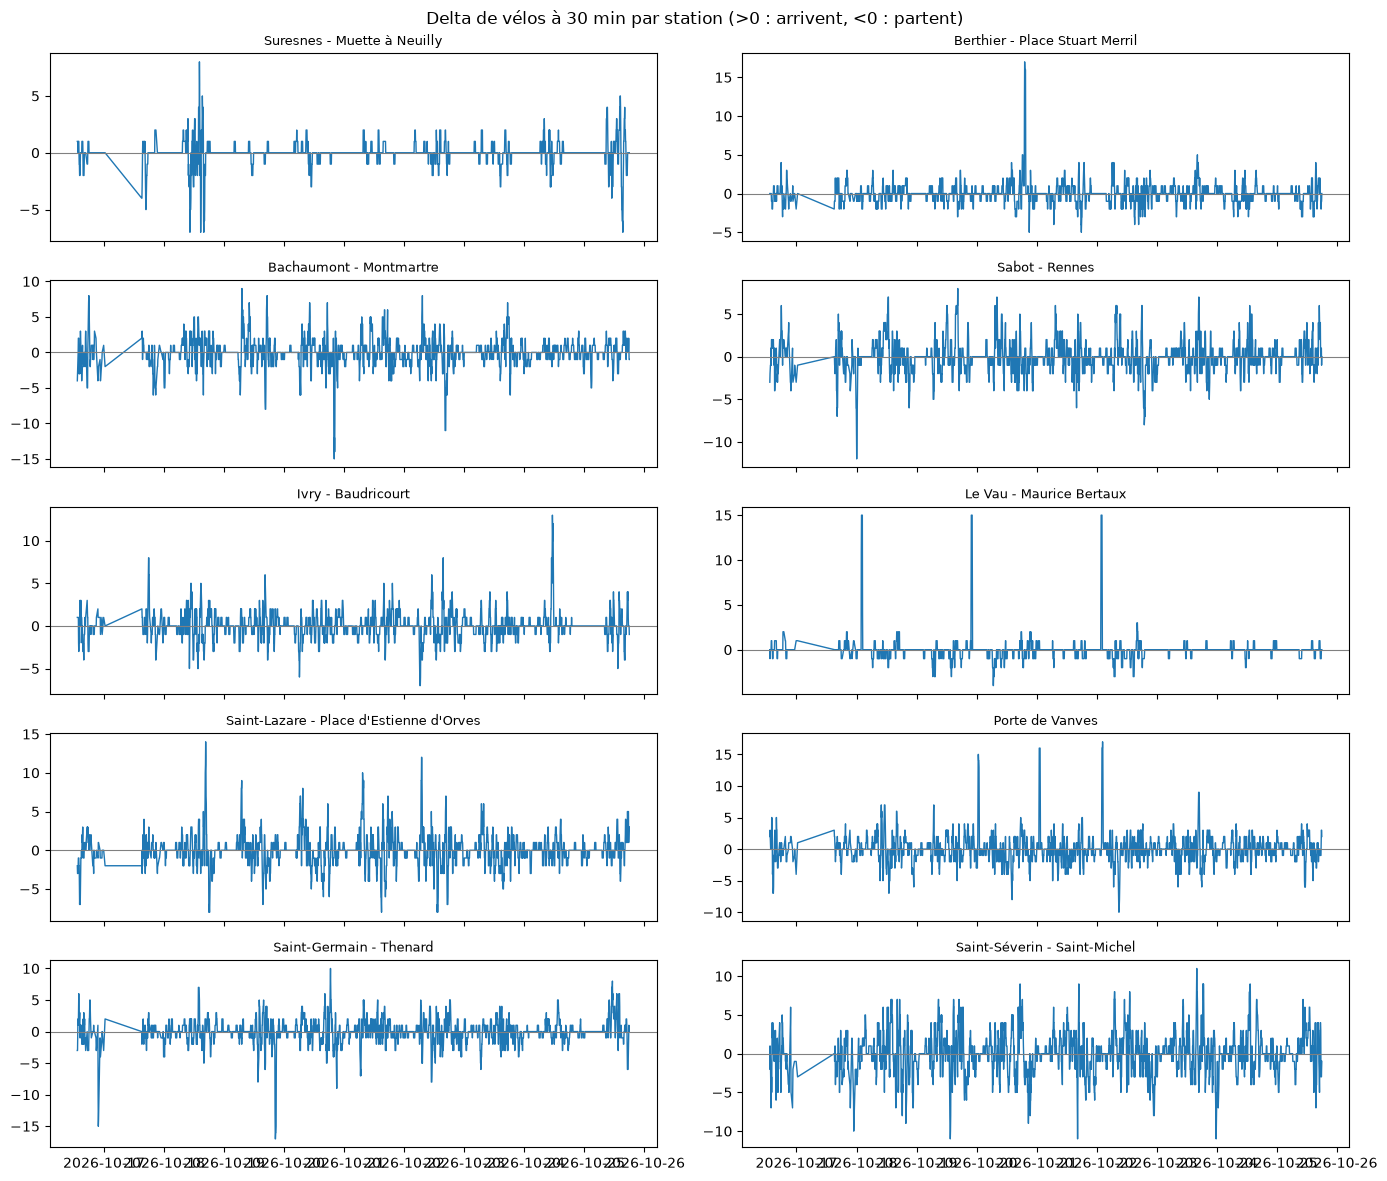

In [ ]:
import matplotlib.pyplot as plt

# 10 stations au hasard (random_state fixe pour retrouver les mêmes)
codes = df["station_code"].drop_duplicates().sample(10, random_state=42)

fig, axes = plt.subplots(5, 2, figsize=(14, 12), sharex=True)

for ax, code in zip(axes.flat, codes):
    d = df[df["station_code"] == code].sort_values("horodatage")
    nom = d["station_name"].iloc[0]
    ax.plot(d["horodatage"], d["delta_t30"], linewidth=1)
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_title(nom, fontsize=9)

fig.suptitle("Delta de vélos à 30 min par station (>0 : arrivent, <0 : partent)")
plt.tight_layout()
plt.show()

Dynamique par l'heure


<Axes: title={'center': 'Delta moyen à 30 min par heure (Paris)'}, xlabel='heure'>

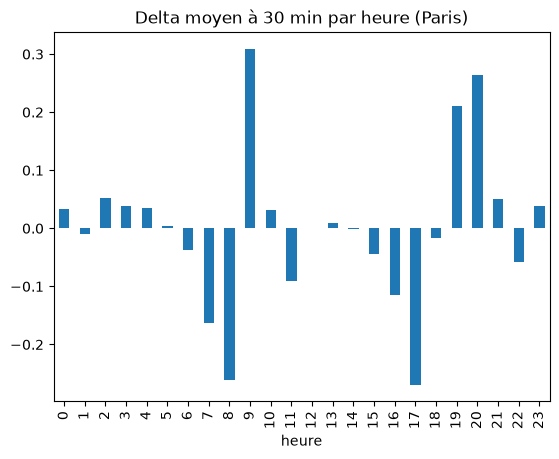

In [ ]:
df["heure"] = df["horodatage"].dt.tz_convert("Europe/Paris").dt.hour
profil_horaire = df.groupby("heure")["delta_t30"].mean()
profil_horaire.plot(kind="bar", title="Delta moyen à 30 min par heure (Paris)")

Les rush hours

Rush hours : [8, 9, 17, 18, 19, 20]


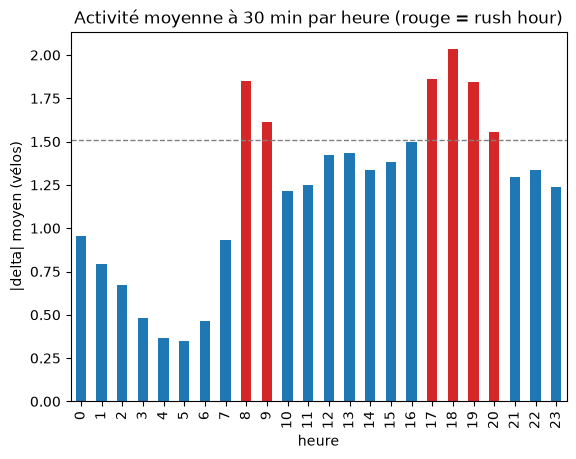

In [ ]:
df["heure"] = df["horodatage"].dt.tz_convert("Europe/Paris").dt.hour
df["delta_abs"] = df["delta_t30"].abs()

# Activité moyenne par heure
activite = df.groupby("heure")["delta_abs"].mean()

# Rush hour = heures dans les 25 % les plus actives
seuil = activite.quantile(0.75)
rush_hours = activite[activite >= seuil].index.tolist()
print("Rush hours :", rush_hours)

# Graphique : rush hours en rouge
couleurs = ["tab:red" if h in rush_hours else "tab:blue" for h in activite.index]
ax = activite.plot(kind="bar", color=couleurs,
                   title="Activité moyenne à 30 min par heure (rouge = rush hour)")
ax.axhline(seuil, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("|delta| moyen (vélos)")

# Étiquette sur chaque ligne
df["rush"] = df["heure"].isin(rush_hours)

En semaine

Rush hours (semaine) : [8, 9, 17, 18, 19, 20]


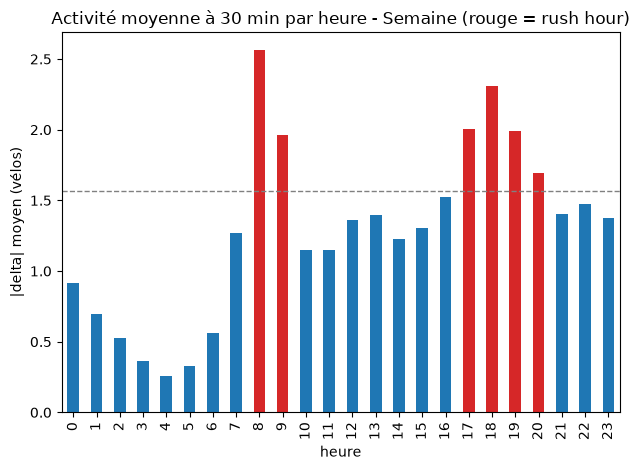

In [ ]:
semaine = df[~df["is_weekend"]]

# Activité moyenne par heure
activite = semaine.groupby("heure")["delta_abs"].mean()

# Rush hour = heures dans les 25 % les plus actives
seuil = activite.quantile(0.75)
rush_hours = activite[activite >= seuil].index.tolist()
print("Rush hours (semaine) :", rush_hours)

# Graphique : rush hours en rouge
couleurs = ["tab:red" if h in rush_hours else "tab:blue" for h in activite.index]
ax = activite.plot(kind="bar", color=couleurs,
                   title="Activité moyenne à 30 min par heure - Semaine (rouge = rush hour)")
ax.axhline(seuil, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("|delta| moyen (vélos)")
plt.tight_layout()
plt.show()

En weekend

Rush hours (week-end) : [12, 14, 15, 17, 18, 19]


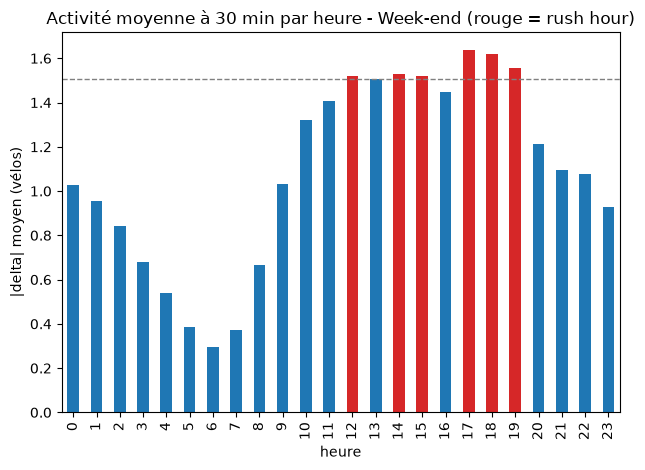

In [ ]:
weekend = df[df["is_weekend"]]

# Activité moyenne par heure
activite = weekend.groupby("heure")["delta_abs"].mean()

# Rush hour = heures dans les 25 % les plus actives
seuil = activite.quantile(0.75)
rush_hours = activite[activite >= seuil].index.tolist()
print("Rush hours (week-end) :", rush_hours)

# Graphique : rush hours en rouge
couleurs = ["tab:red" if h in rush_hours else "tab:blue" for h in activite.index]
ax = activite.plot(kind="bar", color=couleurs,
                   title="Activité moyenne à 30 min par heure - Week-end (rouge = rush hour)")
ax.axhline(seuil, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("|delta| moyen (vélos)")
plt.tight_layout()
plt.show()